# **Dataset Iris**

O dataset Iris (também conhecido como Iris de Fisher) é um dos conjuntos de dados mais famosos e amplamente utilizados na história da estatística, do aprendizado de máquina (Machine Learning) e do reconhecimento de padrões.

Criado pelo estatístico e biólogo britânico Ronald Fisher em seu artigo de 1936 ("The use of multiple measurements in taxonomic problems"), o dataset foi coletado originalmente pelo botânico Edgar Anderson para quantificar a variação morfológica de flores de íris em três espécies relacionadas.

## **1. Estrutura e Composição do Dataset**
* O conjunto de dados é pequeno, limpo e bem equilibrado, tornando-o ideal para ensino e testes de algoritmos:

* Número de Instâncias (Amostras): 150 amostras (flores).

* Distribuição de Classes: 50 amostras para cada uma das 3 espécies.

* Número de Atributos (Variáveis): 4 atributos numéricos contínuos (medidos em centímetros).

## **2. Os Atributos (Features)**
* Para cada flor analisada, foram medidas quatro características:

* Comprimento da Sépala (Sepal Length)

* Largura da Sépala (Sepal Width)

* Comprimento da Pétala (Petal Length)

* Largura da Pétala (Petal Width)


## **Importação das bibliotecas**

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

## **Carregar dados**

In [19]:

iris = load_iris()
X = iris.data
y_true = iris.target  # rótulos reais (só para validação)

## **Padronizar**

In [20]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## **Método do Cotovelo + Silhueta para escolher k**

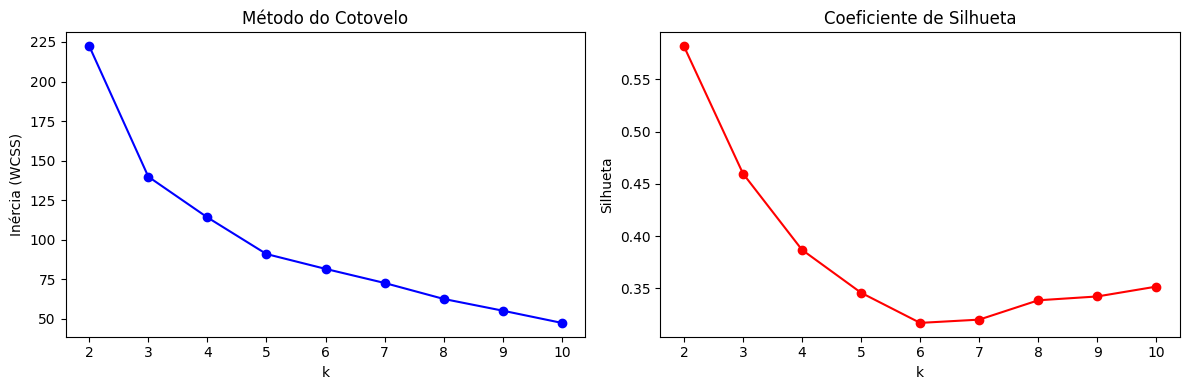

In [21]:
inercia, silhuetas = [], []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inercia.append(km.inertia_)
    silhuetas.append(silhouette_score(X_scaled, labels))


fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K_range, inercia, 'bo-')
ax[0].set_xlabel('k'); ax[0].set_ylabel('Inércia (WCSS)')
ax[0].set_title('Método do Cotovelo')
ax[1].plot(K_range, silhuetas, 'ro-')
ax[1].set_xlabel('k'); ax[1].set_ylabel('Silhueta')
ax[1].set_title('Coeficiente de Silhueta')
plt.tight_layout(); plt.show()

In [22]:
labels

array([6, 2, 2, 2, 6, 0, 6, 6, 2, 2, 0, 6, 2, 2, 0, 0, 0, 6, 0, 0, 6, 0,
       6, 6, 6, 2, 6, 6, 6, 2, 2, 6, 0, 0, 2, 6, 6, 6, 2, 6, 6, 2, 2, 6,
       0, 2, 0, 2, 0, 6, 1, 1, 1, 4, 1, 9, 1, 4, 1, 9, 4, 9, 4, 9, 9, 1,
       9, 9, 4, 4, 1, 9, 8, 9, 1, 1, 1, 1, 9, 4, 4, 4, 9, 8, 9, 1, 1, 4,
       9, 4, 4, 1, 4, 4, 9, 9, 9, 9, 4, 9, 3, 8, 5, 8, 3, 5, 4, 5, 8, 7,
       3, 8, 3, 8, 8, 3, 3, 7, 5, 4, 3, 8, 5, 8, 3, 5, 8, 8, 8, 5, 5, 7,
       8, 8, 8, 5, 3, 3, 8, 3, 3, 3, 8, 3, 3, 3, 8, 3, 3, 8], dtype=int32)

In [23]:
# 4. K-Means com k=3 (sabemos que há 3 espécies)
km = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=42)
labels = km.fit_predict(X_scaled)

In [26]:
labels

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 2,
       0, 0, 0, 0, 2, 0, 0, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 2, 2, 2, 2, 2,
       2, 0, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0], dtype=int32)

In [24]:
# 5. Avaliação
print(f"Inércia final: {km.inertia_:.2f}")
print(f"Silhueta: {silhouette_score(X_scaled, labels):.3f}")


Inércia final: 139.82
Silhueta: 0.460


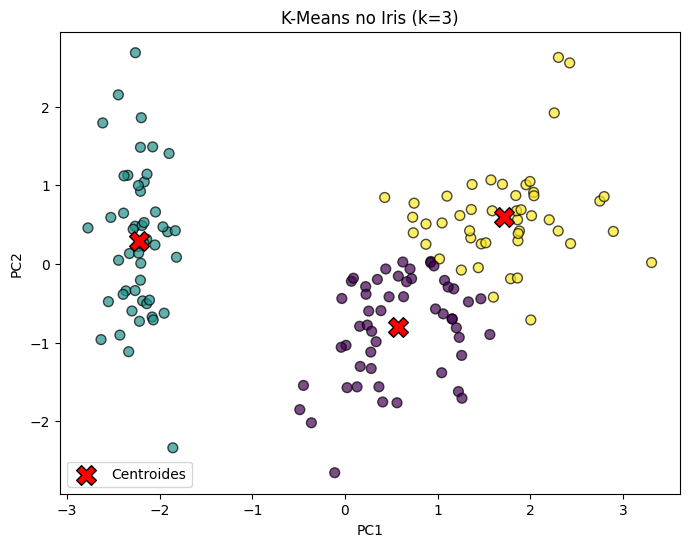

In [30]:
# 6. Visualização com PCA (2D)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1],c=labels, cmap='viridis',
            s=50, alpha=0.7, edgecolor='k')
centroides_pca = pca.transform(km.cluster_centers_)
plt.scatter(centroides_pca[:, 0], centroides_pca[:, 1],
            c='red', marker='X', s=200, edgecolor='k', label='Centroides')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('K-Means no Iris (k=3)')
plt.legend(); plt.show()